# Lab 2 · Multi-partition experiments (Keras)
**Machine Learning for Sound and Music**

With a single 80/20 split the test set has 200 songs, so one song is worth 0.5 pp and a lucky or unlucky partition can suggest a spurious winner. This notebook repeats the main Lab 2 models on **five partitions** (seeds 42–46) and runs some thing necessary for theresearch questions 6, 7 and 8. It produces:

- the test predictions of every model in the common format `song, y_true, y_pred, p_0..p_9`, which the `analysis` notebook reads (McNemar tests, error overlap, ensembles, cost comparison);
- the training / inference cost of every model (`costs.csv`);
- the learning curve, kernel-shape and depth/parameter sweeps.

**Models trained here:** the CNN from scratch (Task 1 configuration), VGG16 fine-tuned (Task 2 configuration, last two blocks unfrozen) and frozen VGG16 embeddings + logistic regression. The Lab 1 descriptor models are retrained on the same partitions in `lab1_retraining`; the pretrained-model comparison on the main partition is in `task_2`.

The hyperparameters of the CNN and of VGG16 are those selected with the *validation* set in Task 1 and Task 2. Partitions are stratified 80/20 splits by song, stored in `results_lab2/splits/` and shared by all notebooks, so every model is trained and tested on exactly the same songs. Test predictions are produced once per model and partition.

In relation to the questions that are going to be mentioned later in the analysis:
| Section | Research question | Output |
|---|---|---|
| 5 | Q1, Q2, Q3, Q4, Q5, Q9, Q10 | `preds/cnn_scratch__seed{S}.csv`, `preds/vgg16_ft__seed{S}.csv`, `preds/vgg16_emb_logreg__seed{S}.csv`, `costs.csv` |
| 6 | Q6 — data size | `learning_curve_cnn.csv` |
| 7 | Q7 — kernel shape | `kernels.csv` |
| 8 | Q8 — depth and parameters | `depth.csv` |
| 9 (optional) | Q9, Q10 | `preds/t2_<run>__seed42.csv` — Task 2 models in the common format |
This is mainly analysed in the following notebok (analysis.ipynb) and also in the Documentation

Also saved: `history/` (per-epoch training curves of every run), `models/` (weights of the CNN from scratch) and `emb_vgg16.npz` (frozen VGG16 embeddings).

## Setup

Results are written to `results_lab2/`, the same folder used by the Lab 1 and analysis notebooks.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os, shutil
from pathlib import Path

def find_dir(root, name, max_depth=6):
    root = Path(root)
    for dirpath, dirnames, _ in os.walk(root, followlinks=True):
        if name in dirnames:
            return Path(dirpath) / name
        depth = len(Path(dirpath).relative_to(root).parts)
        dirnames[:] = [] if depth >= max_depth else [d for d in dirnames if not d.startswith(".")]
    return None

PROJECT = None
if PROJECT is None:
    PROJECT = find_dir("/content/drive/MyDrive", "music-genre-classification-2")
assert PROJECT is not None, "Project folder not found in Drive"

SRC_IMAGES   = PROJECT / "data" / "images_original"
LOCAL_IMAGES = Path("/content/data/images_original")
WAV_DIR      = PROJECT / "data" / "genres_original"       # not used here (VGGish is in task_2)
OUT          = PROJECT / "results_lab2"                   # SAME folder used by the Lab 1 and analysis notebooks
(OUT / "preds").mkdir(parents=True, exist_ok=True); (OUT / "splits").mkdir(exist_ok=True)
(OUT / "history").mkdir(exist_ok=True); (OUT / "models").mkdir(exist_ok=True)

n_local = len(list(LOCAL_IMAGES.glob("*/*.png"))) if LOCAL_IMAGES.exists() else 0
if n_local < 900:
    print("Copying spectrograms to /content/data ...")
    shutil.copytree(SRC_IMAGES, LOCAL_IMAGES, dirs_exist_ok=True, ignore=shutil.ignore_patterns(".DS_Store", "._*"))
print("Project:", PROJECT, "| local PNG files:", len(list(LOCAL_IMAGES.glob("*/*.png"))))

Mounted at /content/drive
Copying spectrograms to /content/data ...
Project: /content/drive/MyDrive/MSC/music-genre-classification-2 | local PNG files: 999


In [ ]:
import gc, re, json, time, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

warnings.filterwarnings("ignore", category=FutureWarning)   # cosmetic: hides a pandas concat warning

SEEDS    = [42, 43, 44, 45, 46]     # 42 = main partition (same as Task 1 / Task 2 / retrained Lab 1)
LC_SEEDS = SEEDS[:3]                # seeds for the sweeps (questions 6, 7, 8); raise to 5 if time allows
WEIGHTS  = "imagenet"               # None = random initialisation (debugging only)

# --- Selected configuration (chosen with the VALIDATION set in Task 1 / Task 2) ---
CNN_CFG    = dict(filters=(32, 64, 128, 256), kernel=(3, 3), dropout=0.0, augment=True, lr=1e-3, size=(128, 192))
CNN_EPOCHS = 39                     # best_epoch of the Task 1 search (40-epoch cosine schedule)
VGG_SIZE   = (160, 240)             # height x width of the VGG16 input (aspect ratio of the crop)
VGG_FROM   = "block4"               # block from which the network is unfrozen: "block5", "block4"... ("block1" ≈ whole network)
VGG_HEAD_EPOCHS, VGG_FT_EPOCHS = 30, 30
CROP = (55, 37, 387, 250)           # (left, top, right, bottom): spectrogram only, no frame or axes
SAVE_MODELS = ("cnn_scratch",)       # models whose weights are saved in OUT/models (e.g. to extract embeddings later); add "vgg16_ft" (≈60 MB per seed) if needed

def set_seed(s):
    random.seed(s); np.random.seed(s); keras.utils.set_random_seed(s)
set_seed(42)
gpus = tf.config.list_physical_devices("GPU"); print("TF", tf.__version__, "| GPUs:", gpus)
if not gpus: print("WARNING: no GPU available; training will be very slow.")

TF 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
pat = re.compile(r"^([a-z]+)(\d{5})\.png$")
rows = []
for gdir in sorted(p for p in LOCAL_IMAGES.iterdir() if p.is_dir()):
    for f in sorted(gdir.glob("*.png")):
        m = pat.match(f.name)
        if m: rows.append(dict(song=f"{m.group(1)}.{m.group(2)}", genre=m.group(1), path=str(f)))
songs = pd.DataFrame(rows)
GENRES = sorted(songs.genre.unique()); songs["label"] = songs.genre.map({g: i for i, g in enumerate(GENRES)})
SONGS = songs.song.tolist(); GENRE_OF = dict(zip(songs.song, songs.genre)); y_all = songs.label.to_numpy()
print(len(songs), "songs")

SONGS_FILE = OUT / "songs.json"          # shared by Lab 1 and Lab 2: they must be the same songs
if SONGS_FILE.exists():
    assert json.load(open(SONGS_FILE)) == SONGS, "The Lab 1 song list and the image song list do not match"
else:
    json.dump(SONGS, open(SONGS_FILE, "w"))

def load_or_make_split(seed):
    """80/20 split by song, stratified by genre. Stored in OUT/splits (shared with Lab 1)."""
    f = OUT / "splits" / f"seed{seed}.json"
    if f.exists():
        return json.load(open(f))
    tr, te = train_test_split(SONGS, test_size=0.2, stratify=[GENRE_OF[s] for s in SONGS], random_state=seed)
    split = dict(train=sorted(tr), test=sorted(te)); json.dump(split, open(f, "w")); return split

idx_of = lambda names: songs.index[songs.song.isin(set(names))].to_numpy()

s42 = load_or_make_split(42)
print("seed 42 -> train/test:", len(s42["train"]), len(s42["test"]))
for cand in [PROJECT / "results_task1" / "split_ids.json"]:
    if cand.exists():
        print("Same test set as Task 1?", sorted(json.load(open(cand))["test"]) == s42["test"])

999 songs
seed 42 -> train/test: 799 200
Same test set as Task 1? True


In [ ]:
ARR = {}
def get_arr(h, w):
    """Cropped and resized spectrograms (N,h,w,3) uint8, in the order of `songs`."""
    if (h, w) not in ARR:
        ARR[(h, w)] = np.stack([np.asarray(Image.open(p).convert("RGB").crop(CROP).resize((w, h), Image.BILINEAR)) for p in songs.path])
    return ARR[(h, w)]
get_arr(*CNN_CFG["size"]); get_arr(*VGG_SIZE)
print({k: v.shape for k, v in ARR.items()})

def save_preds(model, seed, names, y_true, proba):
    df = pd.DataFrame(proba, columns=[f"p_{i}" for i in range(proba.shape[1])])
    df.insert(0, "y_pred", proba.argmax(1)); df.insert(0, "y_true", np.asarray(y_true)); df.insert(0, "song", np.asarray(names))
    df.to_csv(OUT / "preds" / f"{model}__seed{seed}.csv", index=False)

pred_done = lambda model, seed: (OUT / "preds" / f"{model}__seed{seed}.csv").exists()

COSTS_CSV = OUT / "costs.csv"
def log_cost(model, seed, train_time_s, infer_ms, size_mb, params=np.nan):
    row = dict(model=model, seed=seed, train_time_s=train_time_s, infer_ms_per_song=infer_ms, size_mb=size_mb, params=params)
    df = pd.read_csv(COSTS_CSV) if COSTS_CSV.exists() else pd.DataFrame(columns=list(row))
    df = df[~((df.model == model) & (df.seed == seed))]
    pd.concat([df, pd.DataFrame([row])], ignore_index=True).to_csv(COSTS_CSV, index=False)

def upsert(csv, row, keys):
    f = OUT / csv
    df = pd.read_csv(f) if f.exists() else pd.DataFrame(columns=list(row))
    if len(df):
        same = np.logical_and.reduce([df[k] == row[k] for k in keys])
        df = df[~same]
    pd.concat([df, pd.DataFrame([row])], ignore_index=True).to_csv(f, index=False)

def done_in(csv, **kw):
    f = OUT / csv
    if not f.exists(): return False
    df = pd.read_csv(f)
    return bool(len(df) and np.logical_and.reduce([df[k] == v for k, v in kw.items()]).any())

n_params = lambda m: int(sum(np.prod(tuple(w.shape)) for w in m.trainable_weights))
softmax = lambda z: np.exp(z - z.max(1, keepdims=True)) / np.exp(z - z.max(1, keepdims=True)).sum(1, keepdims=True)

{(128, 192): (999, 128, 192, 3), (160, 240): (999, 160, 240, 3)}


## CNN from scratch (Task 1)

**`simple_cnn`** is the Task 1 network: a stack of 3 × 3 convolution → batch normalisation → ReLU → 2 × 2 max-pooling blocks, followed by global average pooling, dropout and a dense layer with 10 logits.

**`run_cnn`** trains a CNN on the training songs of one partition with AdamW (weight decay 1e-4) and a cosine schedule, **without a validation set** (fixed number of epochs), and evaluates it once on the 200 test songs. Normalisation statistics are computed on the training songs only. Besides accuracy it records the training accuracy, the per-epoch history and the cost. `frac < 1` trains on a stratified subset of the training songs (learning curve, Section 6).

In [ ]:
def spec_mask(x, y, H, W, fmask=16, tmask=24):
    f = tf.random.uniform([], 0, fmask + 1, tf.int32); f0 = tf.random.uniform([], 0, H - f + 1, tf.int32)
    t = tf.random.uniform([], 0, tmask + 1, tf.int32); t0 = tf.random.uniform([], 0, W - t + 1, tf.int32)
    rows, cols = tf.range(H), tf.range(W)
    mask = ((rows >= f0) & (rows < f0 + f))[:, None] | ((cols >= t0) & (cols < t0 + t))[None, :]
    return tf.where(mask[:, :, None], 0.0, x), y

def make_ds_arr(X, idx, mean, std, augment=False, bs=32, shuffle=False, seed=42):
    H, W = X.shape[1:3]
    x = (X[idx].astype("float32") / 255. - mean) / std
    ds = tf.data.Dataset.from_tensor_slices((x, y_all[idx]))
    if shuffle: ds = ds.shuffle(len(idx), seed=seed)
    if augment: ds = ds.map(lambda a, b: spec_mask(a, b, H, W), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(bs).prefetch(tf.data.AUTOTUNE)

def simple_cnn(h, w, filters, kernel, dropout, n_classes=10):
    inp = keras.Input(shape=(h, w, 3)); x = inp
    for f in filters:
        x = layers.Conv2D(f, kernel, padding="same")(x)     # kernel = (height = frequency, width = time)
        x = layers.BatchNormalization()(x); x = layers.ReLU()(x); x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x); x = layers.Dropout(dropout)(x)
    return keras.Model(inp, layers.Dense(n_classes)(x))      # logits

def music_cnn(h, w, n_filters=32, dropout=0.3, n_classes=10):
    """Approximation of the "musical" CNN of Pons et al. (2016): PARALLEL branches of filters that are tall in
    frequency (timbre) and wide in time (rhythm), with pooling over the whole axis they cover, and concatenation."""
    inp = keras.Input(shape=(h, w, 3)); feats = []
    for fr in (0.7, 0.4):                                    # timbre: filters spanning 70% / 40% of the mel bands
        b = layers.Conv2D(n_filters, (max(1, int(h * fr)), 7), padding="valid")(inp)
        b = layers.ReLU()(layers.BatchNormalization()(b))
        b = layers.MaxPooling2D((b.shape[1], 1))(b)          # max over all the remaining frequency axis
        feats += [layers.GlobalMaxPooling2D()(b), layers.GlobalAveragePooling2D()(b)]
    for fr in (0.15, 0.30):                                  # rhythm: filters of 1 band and 15% / 30% of the duration
        b = layers.Conv2D(n_filters, (1, max(1, int(w * fr))), padding="same")(inp)
        b = layers.ReLU()(layers.BatchNormalization()(b))
        b = layers.AveragePooling2D((h, 1))(b)               # average over the whole frequency axis
        feats += [layers.GlobalMaxPooling2D()(b), layers.GlobalAveragePooling2D()(b)]
    x = layers.Dropout(dropout)(layers.Concatenate()(feats))
    return keras.Model(inp, layers.Dense(n_classes)(x))

def run_cnn(seed, tag="cnn_scratch", cfg=None, model_fn=None, epochs=CNN_EPOCHS, sched_epochs=40, frac=1.0, save=True, bs=32):
    """Trains a CNN on the train set of partition `seed` (no validation set: fixed number of epochs) and evaluates it on its test set."""
    cfg = {**CNN_CFG, **(cfg or {})}; h, w = cfg["size"]; X = get_arr(h, w)
    split = load_or_make_split(seed); tr_songs = split["train"]
    if frac < 1:
        tr_songs, _ = train_test_split(tr_songs, train_size=frac, stratify=[GENRE_OF[s] for s in tr_songs], random_state=seed)
    idx_tr, idx_te = idx_of(tr_songs), idx_of(split["test"])
    t = X[idx_tr].astype("float32") / 255.; mean, std = t.mean((0, 1, 2)), t.std((0, 1, 2)); del t

    set_seed(seed); keras.backend.clear_session()
    model = model_fn(h, w) if model_fn else simple_cnn(h, w, cfg["filters"], cfg["kernel"], cfg["dropout"])
    steps = int(np.ceil(len(idx_tr) / bs)) * sched_epochs
    model.compile(optimizer=keras.optimizers.AdamW(learning_rate=keras.optimizers.schedules.CosineDecay(cfg["lr"], steps), weight_decay=1e-4),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
    t0 = time.time()
    h = model.fit(make_ds_arr(X, idx_tr, mean, std, cfg["augment"], bs, True, seed), epochs=epochs, verbose=0, shuffle=False)
    train_s = time.time() - t0
    hist = pd.DataFrame(h.history); hist.insert(0, "epoch", range(1, len(hist) + 1))          # train loss and accuracy per epoch
    hist.to_csv(OUT / "history" / (f"{tag}__seed{seed}" + (f"__frac{int(round(frac * 100))}" if frac < 1 else "") + ".csv"), index=False)

    ds_te = make_ds_arr(X, idx_te, mean, std, bs=128)
    model.predict(ds_te.take(1), verbose=0)                                   # warm-up
    t0 = time.time(); logits = model.predict(ds_te, verbose=0); infer_ms = (time.time() - t0) / len(idx_te) * 1000
    probs = softmax(logits); acc = float((probs.argmax(1) == y_all[idx_te]).mean())
    train_acc = float(model.evaluate(make_ds_arr(X, idx_tr, mean, std, bs=128), verbose=0)[1])
    params = n_params(model)
    if save:
        save_preds(tag, seed, songs.song.to_numpy()[idx_te], y_all[idx_te], probs)
        log_cost(tag, seed, train_s, infer_ms, params * 4 / 1e6, params)
        if tag in SAVE_MODELS: model.save(OUT / "models" / f"{tag}__seed{seed}.keras")
    del model; keras.backend.clear_session(); gc.collect()
    print(f"[{tag}] seed {seed} frac {frac:.0%}: test {acc:.3f} | train {train_acc:.3f} | {params:,} params | {train_s:.0f}s")
    return dict(model=tag, seed=seed, frac=frac, n_train=len(idx_tr), test_acc=acc, train_acc=train_acc, params=params, train_time_s=train_s)

## Pretrained VGG16: fine-tuning and frozen embeddings + classical classifier

**`run_vgg`** — two-phase fine-tuning of an ImageNet VGG16 (global average pooling, dropout 0.3, dense softmax layer): phase 1 trains the head (Adam, learning rate 1e-3), phase 2 unfreezes the network from `VGG_FROM` onwards and trains it with a much smaller learning rate (1e-5). Early stopping (patience 5) uses a validation set of 10 % of the training songs, drawn from each partition's training songs only; the test set is evaluated once. The validation songs of each partition and the image-resizing implementation (PIL here, `tf.image` in Task 2) differ from Task 2, so the seed-42 result is not expected to equal the Task 2 value exactly.

**Frozen embeddings** — the 512-dimensional global-average-pooled VGG16 embedding does not depend on the partition, so it is computed **once** for all 999 songs (`emb_vgg16.npz`). `run_emb_clf` trains a standardised logistic regression on the embeddings of the training songs of each partition. Its inference cost includes extracting the embedding.

In [ ]:
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_prep

def vgg_ds(X, idx, bs=32, shuffle=False, seed=42):
    ds = tf.data.Dataset.from_tensor_slices((X[idx], y_all[idx]))
    if shuffle: ds = ds.shuffle(len(idx), seed=seed)
    return ds.map(lambda a, b: (vgg_prep(tf.cast(a, tf.float32)), b), num_parallel_calls=tf.data.AUTOTUNE).batch(bs).prefetch(tf.data.AUTOTUNE)

def run_vgg(seed, tag="vgg16_ft", from_block=VGG_FROM, head_epochs=VGG_HEAD_EPOCHS, ft_epochs=VGG_FT_EPOCHS,
            lr_head=1e-3, lr_ft=1e-5, dropout=0.3):
    """Phase 1: head. Phase 2: fine-tuning from `from_block` with a low learning rate. Early stopping uses a
    validation set drawn ONLY from the train set (10 % of the songs); the test set is evaluated once."""
    X = get_arr(*VGG_SIZE)
    split = load_or_make_split(seed)
    tr_songs, va_songs = train_test_split(split["train"], test_size=0.1, stratify=[GENRE_OF[s] for s in split["train"]], random_state=seed)
    idx_tr, idx_va, idx_te = idx_of(tr_songs), idx_of(va_songs), idx_of(split["test"])
    set_seed(seed); keras.backend.clear_session()
    base = keras.applications.VGG16(include_top=False, weights=WEIGHTS, input_shape=VGG_SIZE + (3,)); base.trainable = False
    inp = keras.Input(VGG_SIZE + (3,)); x = base(inp, training=False)
    x = layers.Dropout(dropout)(layers.GlobalAveragePooling2D()(x))
    model = keras.Model(inp, layers.Dense(10, activation="softmax")(x))
    cb = lambda: [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True)]
    comp = lambda lr: model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    tr_ds, va_ds = vgg_ds(X, idx_tr, shuffle=True, seed=seed), vgg_ds(X, idx_va)

    t0 = time.time()
    comp(lr_head); h1 = model.fit(tr_ds, validation_data=va_ds, epochs=head_epochs, callbacks=cb(), verbose=0, shuffle=False)
    first = next(i for i, l in enumerate(base.layers) if l.name.startswith(from_block))
    base.trainable = True
    for l in base.layers[:first]: l.trainable = False
    comp(lr_ft); h2 = model.fit(tr_ds, validation_data=va_ds, epochs=ft_epochs, callbacks=cb(), verbose=0, shuffle=False)
    train_s = time.time() - t0
    hist = pd.concat([pd.DataFrame(h1.history).assign(phase="head"), pd.DataFrame(h2.history).assign(phase="finetune")], ignore_index=True)
    hist.insert(0, "epoch", range(1, len(hist) + 1)); hist.to_csv(OUT / "history" / f"{tag}__seed{seed}.csv", index=False)   # train and val per epoch

    te_ds = vgg_ds(X, idx_te, bs=64)
    model.predict(te_ds.take(1), verbose=0)
    t0 = time.time(); probs = model.predict(te_ds, verbose=0); infer_ms = (time.time() - t0) / len(idx_te) * 1000
    acc = float((probs.argmax(1) == y_all[idx_te]).mean()); params = model.count_params()
    save_preds(tag, seed, songs.song.to_numpy()[idx_te], y_all[idx_te], probs)
    log_cost(tag, seed, train_s, infer_ms, params * 4 / 1e6, params)
    if tag in SAVE_MODELS: model.save(OUT / "models" / f"{tag}__seed{seed}.keras")
    del model, base; keras.backend.clear_session(); gc.collect()
    print(f"[{tag}] seed {seed}: test {acc:.3f} | {params:,} params | {train_s:.0f}s | {infer_ms:.1f} ms/song")
    return acc

# --- Frozen VGG16 embeddings (independent of the partition: computed ONCE for the 999 songs) ---
EMB_FILE = OUT / "emb_vgg16.npz"
def vgg_embeddings():
    if EMB_FILE.exists():
        d = np.load(EMB_FILE); return d["E"], float(d["ms"])
    X = get_arr(*VGG_SIZE)
    base = keras.applications.VGG16(include_top=False, weights=WEIGHTS, input_shape=VGG_SIZE + (3,), pooling="avg")
    t0 = time.time(); E = base.predict(vgg_ds(X, np.arange(len(X)), bs=64), verbose=0); ms = (time.time() - t0) / len(X) * 1000
    np.savez(EMB_FILE, E=E, ms=ms); return E, ms

def run_emb_clf(seed, E, emb_ms, tag, make_clf=lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))):
    split = load_or_make_split(seed); idx_tr, idx_te = idx_of(split["train"]), idx_of(split["test"])
    clf = make_clf()
    t0 = time.time(); clf.fit(E[idx_tr], y_all[idx_tr]); train_s = time.time() - t0
    t0 = time.time(); probs = clf.predict_proba(E[idx_te]); clf_ms = (time.time() - t0) / len(idx_te) * 1000
    acc = float((probs.argmax(1) == y_all[idx_te]).mean())
    save_preds(tag, seed, songs.song.to_numpy()[idx_te], y_all[idx_te], probs)
    log_cost(tag, seed, train_s, emb_ms + clf_ms, E.shape[1] * 10 * 4 / 1e6, E.shape[1] * 10 + 10)   # cost = extract the embedding + classify
    print(f"[{tag}] seed {seed}: test {acc:.3f}")
    return acc

## Main models × 5 partitions

The three models are trained on each of the five partitions. A model is skipped if its predictions file already exists. The last cell summarises the test accuracy of **every** model whose predictions are stored in `preds/` (including the Lab 1 models trained in `lab1_retraining`): one column per partition, plus the mean and the sample standard deviation (n − 1) over partitions.

In [ ]:
E_vgg, emb_ms = vgg_embeddings()
print("VGG16 embeddings:", E_vgg.shape, f"| {emb_ms:.1f} ms/song")

for seed in SEEDS:
    if not pred_done("cnn_scratch", seed):       run_cnn(seed, "cnn_scratch")
    if not pred_done("vgg16_ft", seed):          run_vgg(seed, "vgg16_ft")
    if not pred_done("vgg16_emb_logreg", seed):  run_emb_clf(seed, E_vgg, emb_ms, "vgg16_emb_logreg")

# quick summary
acc = {}
for f in sorted((OUT / "preds").glob("*__seed*.csv")):
    d = pd.read_csv(f); m, s = f.stem.split("__seed"); acc.setdefault(m, {})[int(s)] = (d.y_true == d.y_pred).mean()
pd.DataFrame(acc).T.assign(mean=lambda d: d.mean(1), std=lambda d: d.std(1)).round(3)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
VGG16 embeddings: (999, 512) | 12.0 ms/song
[cnn_scratch] seed 42 frac 100%: test 0.805 | train 0.999 | 391,946 params | 86s
[vgg16_ft] seed 42: test 0.710 | 14,719,818 params | 130s | 12.9 ms/song
[vgg16_emb_logreg] seed 42: test 0.660
[cnn_scratch] seed 43 frac 100%: test 0.770 | train 0.996 | 391,946 params | 52s
[vgg16_ft] seed 43: test 0.675 | 14,719,818 params | 133s | 6.9 ms/song
[vgg16_emb_logreg] seed 43: test 0.585
[cnn_scratch] seed 44 frac 100%: test 0.765 | train 0.996 | 391,946 params | 52s
[vgg16_ft] seed 44: test 0.685 | 14,719,818 params | 156s | 6.7 ms/song
[vgg16_emb_logreg] seed 44: test 0.635
[cnn_scratch] seed 45 frac 100%: test 0.770 | train 0.997 | 391,946 params | 51s
[vgg16_ft] seed 45: test 0.650 | 14,719,818 params | 91s | 6.8 ms/song
[vgg16_emb_logreg] seed 45: test 0.620
[cnn_scratch] seed 46 frac 100%: test 0.750 | train 0.995 | 391,946 params | 53s
[vgg16_ft] seed 46: test 0.665 | 14,719,818 params | 126

,42,43,44,45,46,mean,std
cnn_scratch,0.805,0.770,0.765,0.770,0.750,0.772,0.018
lab1_extra_trees_correlation,0.785,0.845,0.815,0.795,0.805,0.809,0.021
lab1_random_forest_correlation,0.795,0.870,0.835,0.810,0.815,0.825,0.026
lab1_random_forest_without_selection,0.790,0.865,0.805,0.815,0.800,0.815,0.026
vgg16_emb_logreg,0.660,0.585,0.635,0.620,0.580,0.616,0.030
vgg16_ft,0.710,0.675,0.685,0.650,0.665,0.677,0.020


## Should a CNN treat a spectrogram like a photo? Kernel shape (Q7)

Square kernels (3 × 3, 5 × 5) are compared with kernels elongated in frequency (7 × 3) or in time (3 × 7), and with the parallel-branch "musical" CNN (`music_cnn`). Kernel sizes are written *(frequency × time)*.

All variants share the same conditions: Task 1 configuration otherwise, **40 fixed epochs**, and test and training accuracy over the seeds in `LC_SEEDS`.

> In the Task 1 search the 7 × 3 and 3 × 7 kernels reached a very low validation accuracy, but their runs stopped after only 4–7 epochs because of early stopping. Training for a fixed number of epochs on several partitions shows whether that was a real effect or training instability.

In [ ]:
KERNEL_VARIANTS = {
    "square_3x3":      dict(cfg=dict(kernel=(3, 3))),
    "square_5x5":      dict(cfg=dict(kernel=(5, 5))),
    "tall_7x3_freq":   dict(cfg=dict(kernel=(7, 3))),
    "wide_3x7_time":   dict(cfg=dict(kernel=(3, 7))),
    "pons_musical":    dict(model_fn=lambda h, w: music_cnn(h, w)),
}
for seed in LC_SEEDS:
    for name, kw in KERNEL_VARIANTS.items():
        if done_in("kernels.csv", model=name, seed=seed): continue
        r = run_cnn(seed, name, epochs=40, save=False, **kw)
        upsert("kernels.csv", {k: r[k] for k in ("model", "seed", "params", "train_acc", "test_acc", "train_time_s")}, ["model", "seed"])
pd.read_csv(OUT / "kernels.csv").groupby("model")[["params", "train_acc", "test_acc"]].agg(["mean", "std"]).round(3)

[square_3x3] seed 42 frac 100%: test 0.805 | train 0.999 | 391,946 params | 54s
[square_5x5] seed 42 frac 100%: test 0.790 | train 0.997 | 1,081,610 params | 76s
[tall_7x3_freq] seed 42 frac 100%: test 0.795 | train 0.999 | 909,194 params | 91s
[wide_3x7_time] seed 42 frac 100%: test 0.780 | train 0.996 | 909,194 params | 74s
[pons_musical] seed 42 frac 100%: test 0.695 | train 0.807 | 105,194 params | 101s
[square_3x3] seed 43 frac 100%: test 0.790 | train 0.996 | 391,946 params | 54s
[square_5x5] seed 43 frac 100%: test 0.770 | train 0.996 | 1,081,610 params | 64s
[tall_7x3_freq] seed 43 frac 100%: test 0.815 | train 0.996 | 909,194 params | 75s
[wide_3x7_time] seed 43 frac 100%: test 0.760 | train 0.994 | 909,194 params | 67s
[pons_musical] seed 43 frac 100%: test 0.645 | train 0.834 | 105,194 params | 86s
[square_3x3] seed 44 frac 100%: test 0.725 | train 1.000 | 391,946 params | 53s
[square_5x5] seed 44 frac 100%: test 0.755 | train 0.999 | 1,081,610 params | 64s
[tall_7x3_freq] s

params      train_acc        test_acc       
                    mean  std      mean    std     mean    std
model                                                         
pons_musical    105194.0  0.0     0.814  0.017    0.632  0.071
square_3x3      391946.0  0.0     0.998  0.002    0.773  0.043
square_5x5     1081610.0  0.0     0.997  0.001    0.772  0.018
tall_7x3_freq   909194.0  0.0     0.998  0.002    0.788  0.031
wide_3x7_time   909194.0  0.0     0.997  0.003    0.760  0.020

## Depth and number of parameters (Q8)

The six depth / width configurations of the Task 1 search are retrained for 40 fixed epochs on the seeds in `LC_SEEDS`, and test and training accuracy are plotted against the number of trainable parameters. Where the training accuracy keeps rising while the test accuracy stagnates or drops, overfitting starts.

The test set is used here only to **describe** these curves, after the model has already been chosen with the validation set.

[2conv_16-32] seed 42 frac 100%: test 0.555 | train 0.539 | 5,514 params | 36s
[3conv_16-32-64] seed 42 frac 100%: test 0.680 | train 0.723 | 24,458 params | 37s
[3conv_32-64-128] seed 42 frac 100%: test 0.760 | train 0.846 | 94,986 params | 48s
[4conv_16-32-64-128] seed 42 frac 100%: test 0.800 | train 0.962 | 99,210 params | 37s
[4conv_32-64-128-256] seed 42 frac 100%: test 0.805 | train 0.999 | 391,946 params | 53s
[5conv_32-64-128-256-256] seed 42 frac 100%: test 0.770 | train 0.999 | 982,538 params | 59s
[2conv_16-32] seed 43 frac 100%: test 0.570 | train 0.556 | 5,514 params | 30s
[3conv_16-32-64] seed 43 frac 100%: test 0.675 | train 0.736 | 24,458 params | 32s
[3conv_32-64-128] seed 43 frac 100%: test 0.745 | train 0.831 | 94,986 params | 46s
[4conv_16-32-64-128] seed 43 frac 100%: test 0.750 | train 0.946 | 99,210 params | 35s
[4conv_32-64-128-256] seed 43 frac 100%: test 0.775 | train 0.994 | 391,946 params | 53s
[5conv_32-64-128-256-256] seed 43 frac 100%: test 0.820 | train

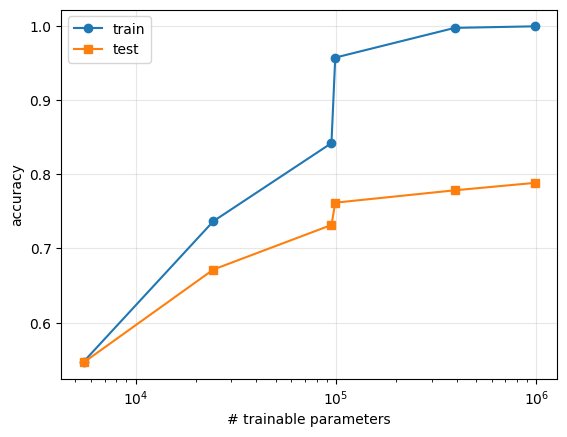

,params,train_acc,test_acc
model,,,
2conv_16-32,5514.0,0.548,0.547
3conv_16-32-64,24458.0,0.737,0.672
3conv_32-64-128,94986.0,0.842,0.732
4conv_16-32-64-128,99210.0,0.957,0.762
4conv_32-64-128-256,391946.0,0.997,0.778
5conv_32-64-128-256-256,982538.0,0.999,0.788


In [ ]:
DEPTH_VARIANTS = {
    "2conv_16-32": (16, 32), "3conv_16-32-64": (16, 32, 64), "3conv_32-64-128": (32, 64, 128),
    "4conv_16-32-64-128": (16, 32, 64, 128), "4conv_32-64-128-256": (32, 64, 128, 256),
    "5conv_32-64-128-256-256": (32, 64, 128, 256, 256),
}
for seed in LC_SEEDS:
    for name, flt in DEPTH_VARIANTS.items():
        if done_in("depth.csv", model=name, seed=seed): continue
        r = run_cnn(seed, name, cfg=dict(filters=flt), epochs=40, save=False)
        upsert("depth.csv", {k: r[k] for k in ("model", "seed", "params", "train_acc", "test_acc", "train_time_s")}, ["model", "seed"])
d = pd.read_csv(OUT / "depth.csv").groupby("model")[["params", "train_acc", "test_acc"]].mean().sort_values("params")
plt.semilogx(d.params, d.train_acc, "o-", label="train"); plt.semilogx(d.params, d.test_acc, "s-", label="test")
plt.xlabel("# trainable parameters"); plt.ylabel("accuracy"); plt.legend(); plt.grid(alpha=.3); plt.show(); d.round(3)

Imports the Task 2 pretrained models into the common prediction format, **for partition 42 only**, so that they can be included in the pairwise comparisons of the analysis notebook (VGG16, ResNet50 and EfficientNetB0 variants listed in `T2_KEYS`; edit the list to choose which). The cell reads `results_task2/runs.csv` and the `probs_<run>.npy` files, checks that the Task 2 test songs are exactly the seed-42 test songs, sorts the rows by song identifier and writes `preds/t2_<run>__seed42.csv` and the matching rows of `costs.csv`.

In [ ]:
T2_DIR, T2_SPLIT = PROJECT / "results_task2", PROJECT / "split_seed42.json"
T2_KEYS = ["vgg16_full", "vgg16_block45", "resnet50_conv45", "resnet50_full", "effnetb0_full"]     # <- the runs to import

def import_task2(keys):
    if not (T2_DIR / "runs.csv").exists() or not T2_SPLIT.exists():
        print("results_task2/runs.csv or split_seed42.json not found: nothing to import."); return
    s2 = json.load(open(T2_SPLIT))
    to_id = lambda p: f"{Path(p).parent.name}.{Path(p).stem[len(Path(p).parent.name):]}"
    ids = np.array([to_id(p) for p in s2["test"]])                              # same order as the rows of probs_*.npy
    assert sorted(ids) == sorted(load_or_make_split(42)["test"]), "The Task 2 test set does not match partition 42"
    ytrue = np.array([GENRES.index(i.split(".")[0]) for i in ids]); order = np.argsort(ids)
    runs = pd.read_csv(T2_DIR / "runs.csv").set_index("model")
    for k in keys:
        f = T2_DIR / f"probs_{k}.npy"
        if not f.exists() or k not in runs.index: print("skipping", k); continue
        probs = np.load(f); assert probs.shape == (len(ids), len(GENRES)), probs.shape
        save_preds(f"t2_{k}", 42, ids[order], ytrue[order], probs[order])
        r = runs.loc[k]; log_cost(f"t2_{k}", 42, r.train_time_s, r.infer_ms_per_song, np.nan, r.params)
        print(f"t2_{k}: test acc {float((probs.argmax(1) == ytrue).mean()):.3f}")
import_task2(T2_KEYS)

## Notes:

GPU kernels are not fully deterministic, so the same configuration and seed can differ by a few songs between runs. For instance, the CNN on partition 42 gives different test accuracies in Task 1, in Section 5 and in the 100 % point of Section 6. Differences of 2–3 pp between single runs should not be interpreted. **Hyperparameters** were chosen on the main partition (seed 42) and kept fixed on the others, so they are slightly optimistic for seed 42; the test songs of the other partitions partly overlap with the songs used for selection. This applies equally to all models.

**Next notebook:** `analysis` (research questions).